<div style="border-left:6px solid #00897B;padding:12px 18px;background:#F5F5F5">
<span style="color:#00897B;font-weight:bold">PAUL MINCHELLA · ONLINE LEARNING · CORRIGÉ</span>
<h1 style="color:#283593">Apprendre un jour à la fois</h1>
<b>OGD, OGD + Ridge et perte newsvendor sur un flux réel de demande</b><br>
Questions, code corrigé et explications · Durée suggérée : 2h30
</div>

Ce TP accompagne [les slides du cours](../Cours_Online_Learning.pdf). On prévoit le nombre journalier
de vélos loués à Washington (Capital Bikeshare) et l'on apprend **après**, jamais avant, la révélation
de chaque observation. Le jeu de données est assez petit pour écrire chaque algorithme à la main,
sans cacher les mises à jour dans une bibliothèque.

**Scénario météo du TP.** On suppose que la température (`temp`), la situation météo (`weathersit`)
et la vitesse du vent (`windspeed`) du jour $t$ sont connues **avant** de prédire la demande de ce jour.
La demande $y_t$ reste inconnue jusqu'après la prédiction. Avec des agrégats météo journaliers réellement indisponibles
à l'avance, cette hypothèse serait un scénario idéal (« oracle météo ») : il faudrait utiliser des prévisions opérationnelles.

### Objectifs

À la fin du TP, vous saurez :

1. décrire une série temporelle et repérer les variables disponibles **avant** la décision ;
2. vérifier les hypothèses des garanties de regret (domaine compact, covariables et cible bornées) ;
3. implémenter OGD projeté pour la perte quadratique, avec et sans ridge ;
4. implémenter OGD pour la perte newsvendor et constater que l'optimum est le quantile critique $\tau = c_b/(c_b+c_h)$ ;
5. évaluer proprement (train puis test, prédire avant d'apprendre) avec le RMSE et le regret moyen.

### Plan

| Partie | Contenu | Slides |
|:--|:--|:--|
| **0** | Packages et données | — |
| **1** | Statistiques descriptives | 9–14 |
| **2** | Apprentissage en ligne : hypothèses, covariables, protocole, OGD, Ridge, Newsvendor | protocole 15–25 ; regret 26–29 ; OGD 44–49 ; régression 53–59 ; stock 60–64 |
| **3** | Métriques finales : RMSE, regret moyen, conclusion | 26–29, 65 |

<div style="border-left:4px solid #000000;padding:8px 14px;background:#E3F2FD;color:#000000">

**Rappel — moyenne mobile**

Une moyenne mobile de fenêtre $w$ remplace chaque valeur par la moyenne de $w$ valeurs voisines. Elle lisse le bruit
journalier pour faire apparaître la tendance et la saisonnalité.

- Moyenne mobile **passée** (causale), qui n'utilise que le passé :

$$
\bar y_t^{\,\text{passée}} = \frac1w \sum_{k=0}^{w-1} y_{t-k}.
$$

- Moyenne mobile **centrée**, qui utilise autant de jours après $t$ qu'avant :

$$
\bar y_t^{\,\text{centrée}} = \frac1w \sum_{k=-\lfloor w/2 \rfloor}^{\lceil w/2 \rceil - 1} y_{t+k}.
$$

La version centrée est mieux alignée sur la série : c'est le bon outil pour la *décrire*. Elle regarde le futur,
elle ne doit donc **jamais** servir à *prévoir*. En pandas : <code style="color:#000000;background:transparent">s.rolling(w).mean()</code> (passée) et
<code style="color:#000000;background:transparent">s.rolling(w, center=True).mean()</code> (centrée).

</div>

# Partie 0 — Packages et données

On n'importe que le nécessaire : NumPy pour l'algèbre, pandas pour le tableau, Matplotlib pour les
figures et deux fonctions de SciPy (une recherche de racine et un solveur linéaire) qui ne servent
qu'à calculer les **comparateurs a posteriori** de la partie 3. Les algorithmes en ligne sont écrits à la main.

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq, linprog
from IPython.display import display

DATA_DIR = Path.cwd() / "online_learning_bike_sharing_data"
DATA_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"

PALETTE = {
    "teal": "#00897B",
    "skyblue": "#81D4FA",
    "blue": "#42A5F5",
    "darkblue": "#283593",
    "orange": "#FB8C00",
    "purple": "#8E24AA",
}
# Une couleur et un style de trait par modèle (le style aide aussi à l'impression N&B).
COLORS = {
    "Naïf (veille)": PALETTE["skyblue"],
    "Naïf (J-7)": PALETTE["teal"],
    "OGD": PALETTE["blue"],
    "OGD + Ridge": PALETTE["darkblue"],
    "Newsvendor (sans covariable)": PALETTE["orange"],
    "Newsvendor (contextuel)": PALETTE["purple"],
}
STYLES = {
    "Naïf (veille)": ":", "Naïf (J-7)": ":",
    "OGD": "-", "OGD + Ridge": "-.",
    "Newsvendor (sans covariable)": "--", "Newsvendor (contextuel)": "-",
}
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2,
    "axes.titleweight": "bold", "axes.labelcolor": "#333333", "lines.linewidth": 2.0,
    "axes.prop_cycle": plt.cycler(color=[PALETTE["teal"], PALETTE["blue"], PALETTE["orange"]]),
})
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 150)

In [2]:
def load_daily_data(data_dir=DATA_DIR, url=DATA_URL):
    """Charge day.csv : cache local s'il existe, sinon téléchargement de l'archive UCI."""
    data_dir.mkdir(parents=True, exist_ok=True)
    csv_path = data_dir / "day.csv"
    if not csv_path.exists():
        print(f"Téléchargement depuis {url} ...")
        with urlopen(url, timeout=60) as response:
            archive = ZipFile(BytesIO(response.read()))
        csv_path.write_bytes(archive.read("day.csv"))  # on ne lit que le membre attendu
    return pd.read_csv(csv_path, parse_dates=["dteday"])


daily = load_daily_data()
print("Données chargées depuis :", DATA_DIR / "day.csv")

Données chargées depuis : /home/paulminchella/Dev/Master-MIASHS/M2_OnlineLearning/Travail_Newsvendor/online_learning_bike_sharing_data/day.csv


# Partie 1 — Statistiques descriptives

**Jeu de données :** [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset),
DOI [10.24432/C5W894](https://doi.org/10.24432/C5W894), licence CC BY 4.0. Nous utilisons `day.csv` :
une ligne par jour, du 1er janvier 2011 au 31 décembre 2012. Citation demandée : Hadi Fanaee-T et João Gama (2013),
*Event labeling combining ensemble detectors and background knowledge*, Progress in Artificial Intelligence.

La variable à prévoir est `cnt`, le nombre total de vélos loués dans la journée.

<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 1.1 — Charger et afficher**

Affichez les premières lignes du jeu de données et son format <code style="color:#000000;background:transparent">(n_row, n_col)</code>.

</div>

In [3]:
display(daily.head())
print("Format (n_row, n_col) :", daily.shape)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Format (n_row, n_col) : (731, 16)


**Réponse.** On obtient $731 \times 16$ : 731 jours et 16 colonnes. Les colonnes se rangent en quatre familles
(description complète dans le tableau en fin de partie 1) :

- **temps :** `instant` (indice 1, …, 731), `dteday` (date) ;
- **calendrier :** `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday` ;
- **météo du jour :** `temp`, `atemp`, `hum`, `windspeed` sont des variables continues déjà normalisées dans $[0,1]$ ; `weathersit` est un code de catégorie (1 = beau … 4 = très mauvais), pas une mesure normalisée ;
- **comptages :** `casual` (occasionnels), `registered` (abonnés) et `cnt` $=$ `casual` $+$ `registered`.

<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 1.2 — Résumé statistique**

Pour chaque variable numérique, calculez moyenne, écart-type, minimum, médiane, maximum, nombre de valeurs manquantes et nombre d'observations. Vérifiez aussi que les dates sont uniques et consécutives, et que <code style="color:#000000;background:transparent">cnt = casual + registered</code>.

</div>

In [4]:
def summary_table(frame):
    """Résumé par variable numérique (on retire l'indice `instant`, sans intérêt statistique)."""
    numeric = frame.select_dtypes(include="number").drop(columns=["instant"])
    return pd.DataFrame({
        "mean": numeric.mean(),
        "std": numeric.std(),
        "min": numeric.min(),
        "median": numeric.median(),
        "max": numeric.max(),
        "n_nan": numeric.isna().sum(),
        "n_obs": numeric.notna().sum(),
    }).round(3)


display(summary_table(daily))

consecutive = daily["dteday"].is_unique and (daily["dteday"].diff().dropna() == pd.Timedelta(days=1)).all()
print("Période :", daily["dteday"].min().date(), "→", daily["dteday"].max().date())
print("Dates uniques et consécutives :", bool(consecutive))
print("cnt = casual + registered :", bool((daily["cnt"] == daily["casual"] + daily["registered"]).all()))

,mean,std,min,median,max,n_nan,n_obs
season,2.497,1.111,1.000,3.000,4.000,0,731
yr,0.501,0.500,0.000,1.000,1.000,0,731
mnth,6.520,3.452,1.000,7.000,12.000,0,731
holiday,0.029,0.167,0.000,0.000,1.000,0,731
weekday,2.997,2.005,0.000,3.000,6.000,0,731
workingday,0.684,0.465,0.000,1.000,1.000,0,731
weathersit,1.395,0.545,1.000,1.000,3.000,0,731
temp,0.495,0.183,0.059,0.498,0.862,0,731
atemp,0.474,0.163,0.079,0.487,0.841,0,731
hum,0.628,0.142,0.000,0.627,0.972,0,731


Période : 2011-01-01 → 2012-12-31
Dates uniques et consécutives : True
cnt = casual + registered : True


**Réponse.**

- **Aucune valeur manquante** : `n_obs` $= 731$ partout, `n_nan` $= 0$. Les dates se suivent sans trou.
- `cnt` varie de quelques dizaines à environ 8 700 vélos par jour, avec une moyenne autour de 4 500 : l'ordre de grandeur est le millier.
- La décomposition `cnt = casual + registered` est exacte. C'est pourquoi `casual` et `registered` **ne peuvent pas** servir
  de covariables : les connaître le jour $t$, c'est connaître la réponse.
- Les variables météo **continues** sont déjà normalisées (température divisée par 41 °C, vent par 67 km/h, etc.) : leurs moyennes ne se lisent pas en unités physiques.
- Les moyennes de `holiday` et `workingday` sont des proportions : environ 3 % de jours fériés et 68 % de jours ouvrés.

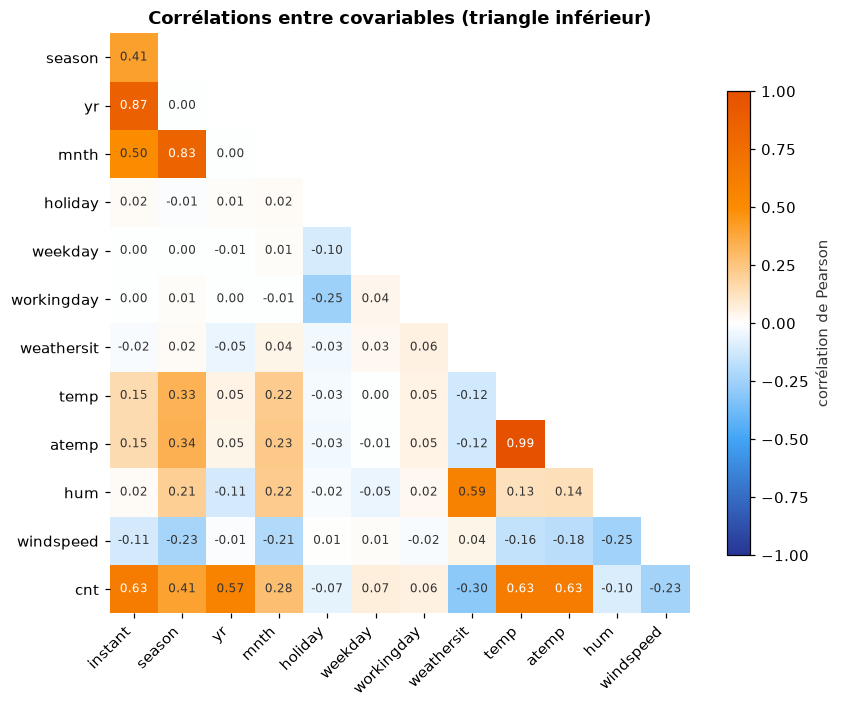

In [5]:
from matplotlib.colors import LinearSegmentedColormap

# Covariables uniquement : on retire l'indice, la cible et ses deux composantes (fuite exacte)
covariates = daily.select_dtypes(include="number").drop(columns=["casual", "registered"])
corr = covariates.corr()  # corrélation de Pearson

# Triangle inférieur strict : on masque la diagonale (toujours 1) et le triangle supérieur (redondant)
mask = np.triu(np.ones_like(corr, dtype=bool))
corr_tri = corr.mask(mask).iloc[1:, :-1]  # retire la 1re ligne et la dernière colonne, vides

# Palette divergente de la charte : bleu foncé (−1) → blanc (0) → orange (+1)
cmap = LinearSegmentedColormap.from_list(
    "charte", [PALETTE["darkblue"], PALETTE["blue"], "#FFFFFF", PALETTE["orange"], "#E65100"])
cmap.set_bad("white")  # cases masquées en blanc

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(np.ma.masked_invalid(corr_tri.to_numpy()), cmap=cmap, vmin=-1, vmax=1)
for i in range(corr_tri.shape[0]):
    for j in range(corr_tri.shape[1]):
        v = corr_tri.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{0.0 if abs(v) < 0.005 else v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(v) > 0.6 else "#333333")
ax.set_xticks(range(corr_tri.shape[1]), corr_tri.columns, rotation=45, ha="right")
ax.set_yticks(range(corr_tri.shape[0]), corr_tri.index)
ax.grid(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="corrélation de Pearson")
ax.set_title("Corrélations entre covariables (triangle inférieur)")
plt.tight_layout()
plt.show()

<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 1.3 — Tracer la série**

Tracez la série observée <code style="color:#000000;background:transparent">cnt</code> en fonction de la date. Qu'observez-vous ?

</div>

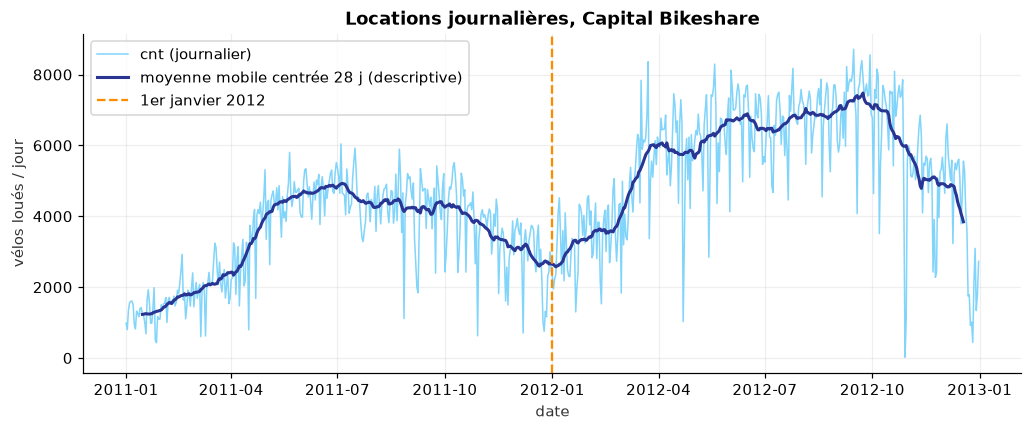

Minimum : 22 vélos le 2012-10-29


In [6]:
fig, ax = plt.subplots()
ax.plot(daily["dteday"], daily["cnt"], color=PALETTE["skyblue"], lw=1, label="cnt (journalier)")
ax.plot(daily["dteday"], daily["cnt"].rolling(28, center=True).mean(), color=PALETTE["darkblue"],
        label="moyenne mobile centrée 28 j (descriptive)")
ax.axvline(pd.Timestamp("2012-01-01"), color=PALETTE["orange"], ls="--", lw=1.5, label="1er janvier 2012")
ax.set(title="Locations journalières, Capital Bikeshare", xlabel="date", ylabel="vélos loués / jour")
ax.legend(loc="upper left")
plt.show()

i_min = daily["cnt"].idxmin()
print(f"Minimum : {daily.loc[i_min, 'cnt']} vélos le {daily.loc[i_min, 'dteday'].date()}")

**Réponse.**

1. **Tendance croissante :** 2012 est nettement au-dessus de 2011 (croissance du réseau). La série n'est **pas stationnaire**.
2. **Saisonnalité annuelle :** creux en hiver, pic de mai à septembre.
3. **Forte variabilité journalière** autour de cette saisonnalité (météo, jour de la semaine, fériés).
4. **Valeurs extrêmes ponctuelles :** quelques jours très bas, dont le minimum de fin octobre 2012
   (ouragan Sandy). Une perte quadratique y sera très sensible.

La moyenne mobile **centrée** utilise le futur (voir le rappel du préambule) : elle est réservée à la description et ne doit jamais servir à prévoir.
Le pointillé orange annonce le découpage train (2011) / test (2012) de la partie 2 : le test sera **plus haut** que le train,
une difficulté réelle pour tout modèle.

### Les covariables de `day.csv` en un coup d'œil

| Colonne | Description |
|:--|:--|
| `instant` | Indice de la ligne, de 1 à 731. |
| `dteday` | Date calendaire de l'observation. |
| `season` | Saison : 1 = hiver, 2 = printemps, 3 = été, 4 = automne. |
| `yr` | Année : 0 = 2011, 1 = 2012. |
| `mnth` | Mois, de 1 à 12. |
| `holiday` | 1 si le jour est férié, 0 sinon. |
| `weekday` | Jour de la semaine, de 0 (dimanche) à 6 (samedi). |
| `workingday` | 1 si le jour n'est ni un week-end ni un férié, 0 sinon. |
| `weathersit` | Situation météo, de 1 (dégagé) à 4 (forte pluie, neige, orage). Utilisée au jour $t$, encodée en indicatrices (référence : 1). |
| `temp` | Température normalisée UCI (échelle de référence : 41 °C), conservée dans $[0,1]$ et supposée connue au jour $t$. |
| `atemp` | Température ressentie en °C, divisée par 50 (le maximum). |
| `hum` | Humidité relative, divisée par 100. |
| `windspeed` | Vitesse du vent normalisée UCI (échelle de référence : 67 km/h), conservée dans $[0,1]$ et supposée connue au jour $t$. |
| `casual` | Nombre de locations par des usagers occasionnels (non abonnés). |
| `registered` | Nombre de locations par des abonnés. |
| `cnt` | Total des locations, `casual` + `registered` : **la cible**. |

# Partie 2 — Apprentissage en ligne

## 2.1 Protocole et regret

On joue un jeu répété contre la nature. À chaque jour $t = 1, 2, \dots, T$ :

1. on observe les covariables $\mathbf x_t \in \mathbb R^d$, toutes connues **avant** la décision ;
2. on choisit un paramètre $\theta_t \in \mathcal K$ et on prédit $\widehat y_t = \mathbf x_t^\top \theta_t$ (ou on commande une quantité $q_t$) ;
3. la demande $y_t$ est révélée et on paie la perte $\ell_t(\theta_t)$ ;
4. on corrige : $\theta_{t+1} = \Pi_{\mathcal K}\big(\theta_t - \eta_t\, g_t\big)$ avec $g_t \in \partial \ell_t(\theta_t)$.

**Information disponible.** Les covariables comprennent le calendrier, les retards de demande et
la météo du jour (`temp`, `weathersit`, `windspeed`), supposée observable à l'étape 1.
Les valeurs météo ne sont donc **pas décalées** ; seule la demande est utilisée avec des retards strictement positifs.

C'est l'**Online Gradient Descent projeté** (OGD). Pour la boule $\mathcal K = \{\theta : \|\theta\|_2 \le B\}$, la projection est explicite :
$\Pi_{\mathcal K}(z) = z \cdot \min\{1,\ B/\|z\|_2\}$.

On mesure la qualité par le **regret** : l'écart entre notre perte cumulée et celle du meilleur paramètre **fixe** choisi après coup,
$$
R_T \;=\; \sum_{t=1}^T \ell_t(\theta_t) \;-\; \min_{u \in \mathcal K} \sum_{t=1}^T \ell_t(u).
$$
Aucune hypothèse probabiliste n'est faite sur $(y_t)$ : la suite peut être quelconque, voire adversariale.
Un algorithme est *sans regret* si $R_T/T \to 0$ : en moyenne, il fait asymptotiquement aussi bien que le meilleur choix fixe.

## 2.2 Deux familles de modèles

**(i) Perte quadratique : OGD et OGD + Ridge** (slides 53–59).

| | Perte | Gradient | Mise à jour | Garantie |
|:--|:--|:--|:--|:--|
| OGD | $\ell_t(\theta) = \tfrac12(\mathbf x_t^\top\theta - y_t)^2$ | $e_t\,\mathbf x_t$, avec $e_t = \widehat y_t - y_t$ | $\Pi_{\mathcal K}(\theta_t - \eta\, e_t \mathbf x_t)$ | $R_T \le D\,G\,\sqrt T$ pour $\eta = \frac{D}{G\sqrt T}$ |
| OGD + Ridge | $\widetilde\ell_t(\theta) = \ell_t(\theta) + \tfrac{\lambda}{2}\|\theta\|_2^2$ | $e_t\,\mathbf x_t + \lambda\theta$ | $\Pi_{\mathcal K}\big((1-\eta_t\lambda)\theta_t - \eta_t\, e_t \mathbf x_t\big)$ | $\widetilde R_T \le \frac{G_\lambda^2}{2\lambda}(1+\log T)$ pour $\eta_t = \frac{1}{\lambda t}$ |

avec $D = 2B$ (diamètre de $\mathcal K$), $G = (RB+Y)R$ et $G_\lambda = G + \lambda B$.

- **OGD :** le résidu fixe le signe et l'amplitude de la correction, $\mathbf x_t$ en donne la direction. La perte est convexe
  mais sa hessienne $\mathbf x_t\mathbf x_t^\top$ est de rang 1, donc pas de forte convexité et un regret en $\sqrt T$.
- **Ridge :** la hessienne devient $\mathbf x_t\mathbf x_t^\top + \lambda I_d \succeq \lambda I_d$. La perte est $\lambda$-fortement convexe
  dans **toutes** les directions, d'où un regret logarithmique. Attention : cette garantie porte sur la perte **régularisée**
  $\widetilde\ell_t$, pas sur l'erreur quadratique seule.

**(ii) Perte newsvendor : commander avant de connaître la demande** (slides 60–64).

On commande $q_t \in [0, Q_{\max}]$ avant d'observer $y_t$. Chaque vélo en trop coûte $c_h$, chaque vélo manquant coûte $c_b$ :
$$
\ell_t(q) = c_h\,(q - y_t)_+ + c_b\,(y_t - q)_+ = (c_b + c_h)\,\rho_\tau(y_t - q),
\qquad \tau = \frac{c_b}{c_b + c_h},
$$
où $\rho_\tau(r) = \tau r_+ + (1-\tau)(-r)_+$ est la perte *pinball*. Un sous-gradient est $g_t = c_h$ en cas d'excédent ($q_t > y_t$),
$g_t = -c_b$ en cas de rupture ($q_t < y_t$) et $0$ en cas d'égalité. D'où la règle : **rupture → on monte, excédent → on baisse**,
de façon asymétrique. Avec $\eta = Q_{\max}/(G\sqrt T)$ et $G = \max(c_b, c_h)$, on a $R_T \le Q_{\max}\, G\, \sqrt T$.

**Résultat clé :** pour une demande de loi $F$, le coût espéré est minimal au **quantile critique** $q^\star = F^{-1}(\tau)$.
Sur un échantillon, la meilleure commande constante est le $\tau$-quantile empirique. Nous le vérifierons numériquement.

Le jeu de données ne fournit **pas** de coûts : nous **posons** $c_b = 3$ et $c_h = 1$ (un vélo manquant fait perdre une location,
trois fois plus coûteuse qu'un vélo immobilisé), soit $\tau = 0{,}75$, comme dans le cours. Nous testerons aussi une
version **contextuelle** $q_t = \mathbf x_t^\top\theta_t$, qui apprend un quantile conditionnel avec le même sous-gradient multiplié par $\mathbf x_t$.

<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 2.1 — Les hypothèses s'appliquent-elles ?**

Les garanties de regret reposent sur des hypothèses. Pour chacune, demandez-vous **pourquoi** elle sert dans la preuve et **comment** la garantir sur nos données : le domaine $\mathcal K$ est-il convexe et compact ? Les covariables sont-elles bornées, $\|\mathbf x_t\|_2 \le R$ ? La cible est-elle bornée, $|y_t| \le Y$ ? Les pertes sont-elles convexes ? Quelles hypothèses ne sont **pas** nécessaires ?

</div>

**Réponse.**

| Hypothèse | Rôle dans la preuve | Dans ce TP |
|:--|:--|:--|
| $\mathcal K$ convexe, fermé, borné, non vide | la projection existe et rapproche de tout $u \in \mathcal K$ ; le diamètre $D$ est fini | boule $\{\|\theta\|_2 \le B\}$ avec $B = 2$, donc $D = 4$ ; pour le newsvendor sans covariable, $[0, Q_{\max}]$ et $D = Q_{\max}$ |
| $\|\mathbf x_t\|_2 \le R$ | borne les gradients | **par construction** : intercept $=1$ ; calendrier : somme des carrés $\le 1$ ; $\sin^2+\cos^2=1$ ; température et vent : chacun dans $[0,1]$ ; indicatrices météo : somme des carrés $\le 1$ ; $p$ retards dans $[0,1]$, d'où $R = \sqrt{p+6} = \sqrt{13}$ pour $p=7$ |
| $\mid y_t\mid \le Y$ | borne le résidu, donc le gradient | $y_t = \texttt{cnt}_t / 10\,000 \in [0,1]$, donc $Y = 1$ |
| $\ell_t$ convexe | inégalité de convexité, cœur de la preuve | quadratique : convexe ; ridge : $\lambda$-fortement convexe ; newsvendor : convexe, linéaire par morceaux, non dérivable (on prend un sous-gradient) |
| horizon $T$ connu | pour le pas constant $\eta^\star = D/(G\sqrt T)$ | $T$ = taille de la fenêtre ; sinon on prendrait $\eta_t \propto 1/\sqrt t$ |

**Points de vigilance.**

- Les bornes $B$, $R$ et $Y$ sont **déclarées a priori**, pas estimées sur le test. L'échelle $10\,000$ n'est pas le maximum observé : c'est une capacité plausible.
  Si une demande future dépassait $10\,000$, le théorème ne s'appliquerait plus. Il faudrait le signaler, pas tronquer en silence.
- La météo du jour est **supposée connue avant la décision**, contrairement à la demande du jour. Ce n'est pas une propriété
  garantie par le CSV : en pratique, il faudrait remplacer les agrégats journaliers indisponibles par des prévisions.
- $B$ trop petit restreint le comparateur, ce qui rend le regret facile mais peu informatif. $B$ trop grand dégrade la borne via $D$ et $G$.
- **Inutiles :** l'indépendance, la stationnarité, un modèle génératif. C'est la force du cadre en ligne, et c'est utile ici puisque la série a une tendance.
- Une borne de regret compare au meilleur paramètre **fixe**. Elle ne promet ni une petite erreur absolue ni un bon suivi d'une demande qui dérive.

In [7]:
P = 7                      # nombre de retards de la demande utilisés comme covariables
TARGET_SCALE = 10_000.0    # échelle déclarée a priori : y = cnt / 10 000 ∈ [0, 1]
B = 2.0                    # rayon de K = {θ : ||θ||₂ ≤ B}
C_B, C_H = 3.0, 1.0        # coûts posés : rupture 3× plus chère qu'un excédent
TAU = C_B / (C_B + C_H)    # quantile critique = 0.75
Q_MAX = 1.0                # capacité newsvendor : 10 000 vélos en unités normalisées

WEATHER_LEVELS = (1, 2, 3, 4)  # catégories fixées a priori ; catégorie 1 = référence
# ||x_t||² ≤ 1 (intercept) + 1 (calendrier) + 1 (sin² + cos²)
#             + 1 (temp) + 1 (windspeed) + 1 (indicatrices météo) + P (retards)
R = np.sqrt(P + 6)
Y = 1.0
D = 2 * B
G_SQ = (R * B + Y) * R     # borne du gradient de la perte quadratique sur K
G_NV = max(C_B, C_H)       # newsvendor sans covariable
G_CTX = max(C_B, C_H) * R  # newsvendor contextuel


def theory_table(T):
    """Pas théoriques et bornes de regret moyen R_T / T, pour un horizon T."""
    rows = {
        "OGD (quadratique)": (D, G_SQ),
        "Newsvendor (sans covariable)": (Q_MAX, G_NV),
        "Newsvendor (contextuel)": (D, G_CTX),
    }
    return pd.DataFrame({name: {"D": d, "G": g, "η* = D/(G√T)": d / (g * np.sqrt(T)),
                                "borne R_T/T = DG/√T": d * g / np.sqrt(T)}
                         for name, (d, g) in rows.items()}).T.round(4)


print(f"R = {R:.3f}, Y = {Y}, B = {B}, τ = {TAU}")
print(f"Bornes vérifiées a posteriori : max cnt / échelle = {daily['cnt'].max() / TARGET_SCALE:.3f} ≤ Y = {Y}")
display(theory_table(T=365))
for lam in [0.01, 0.1]:
    G_lam = G_SQ + lam * B
    print(f"Ridge λ = {lam:<5}: borne R̃_T/T = G_λ²(1 + log T)/(2λT) = {G_lam**2 * (1 + np.log(365)) / (2 * lam * 365):.2f}")

R = 3.606, Y = 1.0, B = 2.0, τ = 0.75
Bornes vérifiées a posteriori : max cnt / échelle = 0.871 ≤ Y = 1.0


,D,G,η* = D/(G√T),borne R_T/T = DG/√T
OGD (quadratique),4.0,29.6056,0.0071,6.1985
Newsvendor (sans covariable),1.0,3.0000,0.0174,0.1570
Newsvendor (contextuel),4.0,10.8167,0.0194,2.2647


Ridge λ = 0.01 : borne R̃_T/T = G_λ²(1 + log T)/(2λT) = 829.57
Ridge λ = 0.1  : borne R̃_T/T = G_λ²(1 + log T)/(2λT) = 83.97


## Remarque — borne du regret moyen Ridge

Pour OGD sur la perte régularisée, avec le **pas théorique** $\eta_t=1/(\lambda t)$ et $\lambda>0$ :

$$
\frac{\widetilde R_T}{T}
\le \frac{(G+\lambda B)^2(1+\log T)}{2\lambda T},
\qquad G=(RB+Y)R.
$$

Ici $R=\sqrt{p+6}$ intègre les trois variables météo. Pour tout $\lambda>0$ fixé, cette borne tend vers zéro lorsque $T$ grandit.
À horizon fixé, son minimum en $\lambda$ est atteint pour $\lambda^\star=G/B$ (on minimise $G^2/\lambda+2GB+B^2\lambda$).
**Minimiser cette borne pessimiste ne garantit pas de minimiser le regret réalisé ni le RMSE** :
les hyperparamètres prédictifs restent choisis sur le train seulement.

Le graphique ci-dessous représente cette **borne de référence**, avec l'horizon illustratif $T=365$.
Le code d'apprentissage plafonne le pas à $1/R^2$ : la phase initiale modifie la constante de la garantie ;
la formule affichée n'est donc pas une borne finie exacte de cette variante plafonnée sans terme supplémentaire.


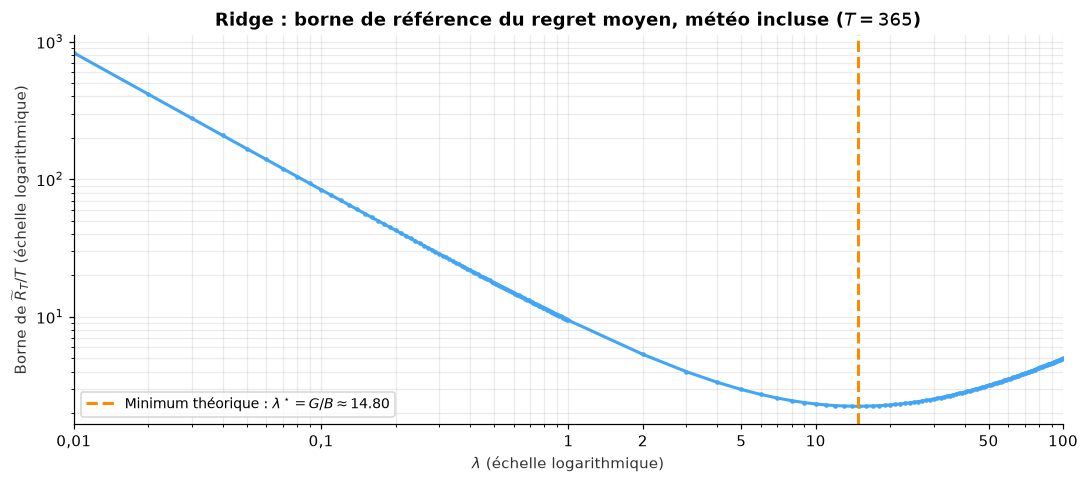

In [8]:
# Borne théorique du regret moyen Ridge, et non borne du gradient.
T_borne = 365

# 0.01, 0.02, ..., 1.00, puis 2, 3, ..., 100 : 199 valeurs, sans doublon.
lambdas = np.concatenate([
    np.arange(1, 101) / 100.0,
    np.arange(2, 101, dtype=float),
])
bornes_gradient = G_SQ + lambdas * B
bornes_regret_moyen = (
    bornes_gradient**2 * (1 + np.log(T_borne))
    / (2 * lambdas * T_borne)
)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(lambdas, bornes_regret_moyen, marker=".", markersize=4, color=PALETTE["blue"])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(0.01, 100)
ax.set_xticks([0.01, 0.1, 1, 2, 5, 10, 50, 100], ["0,01", "0,1", "1", "2", "5", "10", "50", "100"])
ax.set_xlabel(r"$\lambda$ (échelle logarithmique)")
ax.set_ylabel(r"Borne de $\widetilde{R}_T/T$ (échelle logarithmique)")
ax.set_title(
    rf"Ridge : borne de référence du regret moyen, météo incluse ($T={T_borne}$)"
)
lambda_opt_borne = G_SQ / B
ax.axvline(lambda_opt_borne, color=PALETTE["orange"], ls="--",
           label=rf"Minimum théorique : $\lambda^\star=G/B \approx {lambda_opt_borne:.2f}$")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.25)
plt.tight_layout()
plt.show()


Les bornes sont **très pessimistes** : une borne de regret moyen de l'ordre de l'unité est énorme devant des pertes quadratiques
de l'ordre de $10^{-3}$ en unités normalisées. Celle du ridge est même inutilisable pour $\lambda$ petit, à cause du facteur $1/\lambda$.
Ce sont des garanties **pire cas**, valables pour toute suite, pas des prévisions de performance. Le pas théorique $\eta^\star$
fait néanmoins partie de la grille testée plus bas.

<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 2.2 — Préparer les covariables**

Construisez, pour chaque jour $t$, un vecteur $\mathbf x_t = (1, \mathbf z_t, y_{t-1}, \dots, y_{t-p})$ qui ne contient que de l'information disponible **avant** d'observer $y_t$. Ici $\mathbf z_t$ regroupe le calendrier et les variables météo **temp**, **weathersit**, **windspeed** du jour, supposées connues avant la décision. Encodez la situation météo en indicatrices et conservez les échelles normalisées de température et de vent. Le paramètre appris est $\theta_t$, et l'on prédit $\widehat y_t = \mathbf x_t^\top\theta_t$. Quelles colonnes faut-il exclure, et pourquoi ? Vérifiez numériquement que $\|\mathbf x_t\|_2 \le R$ et que les covariables sont causales.

</div>

**Choix retenus.**

- **Calendrier :** `workingday`, `holiday`, $\sin(2\pi j_t/365{,}25)$ et $\cos(2\pi j_t/365{,}25)$,
  où $j_t$ est le jour de l'année. Les deux indicatrices de calendrier ne peuvent pas valoir 1 simultanément.
- **Météo au jour $t$, supposée connue avant la prédiction :**
  - `temp` et `windspeed` restent sur leurs échelles UCI dans $[0,1]$ ; aucune normalisation n'est apprise sur le test ;
  - `weathersit` est une **catégorie**, pas une grandeur continue : on crée les indicatrices
    `weathersit_2`, `weathersit_3`, `weathersit_4`, avec la catégorie 1 comme référence.
    Les catégories possibles 1 à 4 sont fixées a priori, y compris si l'une est absente du train.
    Au plus une de ces trois indicatrices vaut 1, donc leur contribution à la norme au carré est au plus 1.
- **Retards de demande :** $y_{t-1},\dots,y_{t-7}$ seulement. La météo n'est pas retardée sous notre hypothèse ;
  la demande $y_t$ ne fait jamais partie des covariables du jour.
- **Exclus :** `casual` et `registered` (fuite exacte de la cible) ; `instant` (tendance non bornée a priori) ;
  `hum` et `atemp`, non retenues dans cette variante. Aucune observation future n'intervient.
- Avec l'intercept, $d=p+10=17$ colonnes. Les $p=7$ premiers jours servent d'historique : il reste 724 jours utilisables.
  La borne déterministe est $R^2=1+1+1+1+1+1+p=p+6=13$, donc $R=\sqrt{13}$.

**Portée de l'hypothèse météo.** Les agrégats journaliers observés du CSV ne seraient généralement pas disponibles avant
une décision prise en début de journée. Les utiliser ici est autorisé par l'hypothèse explicite du TP ;
pour une application réelle, il faut des prévisions météo disponibles à l'heure de décision.


In [9]:
def build_features(frame, p=P, scale=TARGET_SCALE):
    """Calendrier et météo connus au jour t ; seuls les retards de demande utilisent le passé."""
    weather = frame[["temp", "windspeed"]].to_numpy(dtype=float)
    if not (np.isfinite(weather).all() and ((0 <= weather) & (weather <= 1)).all()):
        raise ValueError("temp et windspeed doivent être finies et normalisées dans [0, 1].")
    if not frame["weathersit"].isin(WEATHER_LEVELS).all():
        raise ValueError("weathersit doit être une catégorie parmi 1, 2, 3, 4.")

    y_all = frame["cnt"].to_numpy(dtype=float) / scale
    angle = 2 * np.pi * frame["dteday"].dt.day_of_year.to_numpy() / 365.25
    feats = pd.DataFrame({
        "intercept": 1.0,
        "workingday": frame["workingday"].astype(float),
        "holiday": frame["holiday"].astype(float),
        "temp": frame["temp"].astype(float),
        "windspeed": frame["windspeed"].astype(float),
        "sin_annual": np.sin(angle),
        "cos_annual": np.cos(angle),
    }, index=frame.index)
    # Encodage fixé sans consulter le train ni le test ; catégorie 1 = référence.
    for level in WEATHER_LEVELS[1:]:
        feats[f"weathersit_{level}"] = frame["weathersit"].eq(level).astype(float)
    for k in range(1, p + 1):
        feats[f"y_lag{k}"] = pd.Series(y_all, index=frame.index).shift(k)
    keep = feats.notna().all(axis=1).to_numpy()  # historique incomplet : les p premiers jours
    return (feats.loc[keep].to_numpy(dtype=float), y_all[keep],
            frame.loc[keep, "dteday"].reset_index(drop=True), list(feats.columns))


X, y, dates, feature_names = build_features(daily)
print("Météo du jour connue avant la décision : temp, weathersit (indicatrices), windspeed.")
print("X :", X.shape, " y :", y.shape, " de", dates.iloc[0].date(), "à", dates.iloc[-1].date())
display(pd.DataFrame(X[:5], columns=feature_names, index=dates[:5].dt.date).round(3))


Météo du jour connue avant la décision : temp, weathersit (indicatrices), windspeed.
X : (724, 17)  y : (724,)  de 2011-01-08 à 2012-12-31


,intercept,workingday,holiday,temp,windspeed,sin_annual,cos_annual,weathersit_2,weathersit_3,weathersit_4,y_lag1,y_lag2,y_lag3,y_lag4,y_lag5,y_lag6,y_lag7
dteday,,,,,,,,,,,,,,,,,
2011-01-08,1.0,0.0,0.0,0.165,0.267,0.137,0.991,1.0,0.0,0.0,0.151,0.161,0.160,0.156,0.135,0.080,0.098
2011-01-09,1.0,0.0,0.0,0.138,0.362,0.154,0.988,0.0,0.0,0.0,0.096,0.151,0.161,0.160,0.156,0.135,0.080
2011-01-10,1.0,1.0,0.0,0.151,0.223,0.171,0.985,0.0,0.0,0.0,0.082,0.096,0.151,0.161,0.160,0.156,0.135
2011-01-11,1.0,1.0,0.0,0.169,0.122,0.188,0.982,1.0,0.0,0.0,0.132,0.082,0.096,0.151,0.161,0.160,0.156
2011-01-12,1.0,1.0,0.0,0.173,0.305,0.205,0.979,0.0,0.0,0.0,0.126,0.132,0.082,0.096,0.151,0.161,0.160


In [10]:
# 1) Bornes déterministes : le calendrier est mutuellement exclusif, la météo est normalisée.
assert daily[["workingday", "holiday"]].isin([0, 1]).all().all()
assert (daily["workingday"] + daily["holiday"] <= 1).all()
norms = np.linalg.norm(X, axis=1)
assert np.isfinite(X).all() and np.isfinite(y).all()
assert np.all(norms <= R + 1e-12), "La borne de norme annoncée est dépassée."
assert np.all(np.abs(y) <= Y), "La cible dépasse l'échelle déclarée : signaler ce dépassement."
print(f"max_t ||x_t||₂ = {norms.max():.3f} ≤ R = {R:.3f} : True")
print(f"max_t |y_t|    = {np.abs(y).max():.3f} ≤ Y = {Y} : True")

# 2) Les trois variables météo entrent bien au jour t, sans décalage.
for col in ["temp", "windspeed"]:
    np.testing.assert_allclose(X[:, feature_names.index(col)], daily[col].iloc[P:])
for level in WEATHER_LEVELS[1:]:
    np.testing.assert_array_equal(
        X[:, feature_names.index(f"weathersit_{level}")],
        daily["weathersit"].iloc[P:].eq(level).to_numpy(dtype=float),
    )
print("Alignement vérifié : météo du jour t, retards de demande strictement passés.")

# 3) Modifier y_t0 ne change aucune covariable des jours ≤ t0.
t0 = 300
row_t0 = t0 - P
perturbed = daily.copy()
perturbed.loc[t0, "cnt"] += 5_000
X_pert, *_ = build_features(perturbed)
np.testing.assert_array_equal(X[:row_t0 + 1], X_pert[:row_t0 + 1])
assert not np.array_equal(X[row_t0 + 1], X_pert[row_t0 + 1])
print("Absence de fuite de cible vérifiée : y_t0 n'affecte que les retards des jours suivants.")

# 4) Modifier toute la météo et la demande futures ne doit pas affecter les jours ≤ t0.
future = daily.copy()
future.loc[t0 + 1:, "cnt"] = 0
for col in ["temp", "windspeed"]:
    future.loc[t0 + 1:, col] = 1 - future.loc[t0 + 1:, col]
future.loc[t0 + 1:, "weathersit"] = future.loc[t0 + 1:, "weathersit"] % 4 + 1
X_future, *_ = build_features(future)
np.testing.assert_array_equal(X[:row_t0 + 1], X_future[:row_t0 + 1])
print("Absence de fuite du futur vérifiée, y compris pour les variables météo.")


max_t ||x_t||₂ = 2.959 ≤ R = 3.606 : True
max_t |y_t|    = 0.871 ≤ Y = 1.0 : True
Alignement vérifié : météo du jour t, retards de demande strictement passés.
Absence de fuite de cible vérifiée : y_t0 n'affecte que les retards des jours suivants.
Absence de fuite du futur vérifiée, y compris pour les variables météo.


<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 2.3 — Train puis test, en prédisant avant d'apprendre**

Découpez chronologiquement : **train = 2011**, **test = 2012**. Écrivez une boucle en ligne qui, chaque jour, **prédit d'abord** puis met à jour avec $y_t$. Comment choisir les hyperparamètres sans regarder le test ? Le modèle doit-il continuer d'apprendre pendant le test ? Enfin, retracez la série en colorant les fenêtres de train et de test.

</div>

**Réponse : quatre règles.**

1. **Prédire, puis apprendre.** La prédiction du jour $t$ est calculée **avant** que $y_t$ ne soit révélé. Mettre à jour d'abord
   et prédire ensuite reviendrait à tricher : on évaluerait un modèle qui a déjà vu la réponse. On stocke une **copie**
   du paramètre $\theta_t$ qui a réellement servi, car la mise à jour suivante le modifierait sinon par aliasing.
2. **Découpage par les dates, sans mélange aléatoire.** On veut prévoir le futur à partir du passé : mélanger les jours ferait
   fuir de l'information de 2012 vers 2011.
3. **Hyperparamètres choisis sur le train seulement.** Pour chaque valeur d'une petite grille, on fait tourner l'algorithme en ligne
   sur 2011 et l'on retient la valeur de perte moyenne minimale. Elle est **figée** ensuite : on ne revient pas en arrière après avoir vu le test.
4. **Sur le test, on continue d'apprendre.** C'est le principe de l'apprentissage en ligne : le modèle repart de son état fin 2011,
   sans remise à zéro de l'horloge $t$, et chaque prédiction de 2012 est faite avant la révélation. Cette évaluation
   *prequentielle* ne voit aucune demande future : elle utilise les demandes passées et, par hypothèse, la météo du jour connue avant la décision.

In [11]:
is_train = (dates < "2012-01-01").to_numpy()
X_train, y_train, dates_train = X[is_train], y[is_train], dates[is_train]
X_test, y_test, dates_test = X[~is_train], y[~is_train], dates[~is_train].reset_index(drop=True)
print(f"Train : {len(y_train)} jours ({dates_train.iloc[0].date()} → {dates_train.iloc[-1].date()})")
print(f"Test  : {len(y_test)} jours ({dates_test.iloc[0].date()} → {dates_test.iloc[-1].date()})")


def run_online(model, X, y):
    """Boucle en ligne : chaque jour, (1) prédire avec θ_t, (2) révéler y_t, (3) mettre à jour."""
    preds = np.empty(len(y))
    params = []
    for t in range(len(y)):
        params.append(np.copy(model.params()))  # copie du paramètre qui sert VRAIMENT à prédire
        preds[t] = model.predict(X[t])          # 1) prédiction AVANT de connaître y_t
        model.update(X[t], y[t])                # 2) y_t révélé → correction
    return preds, np.array(params)


def squared_loss(pred, y):
    return 0.5 * (pred - y) ** 2


def newsvendor_loss(q, y, c_b=C_B, c_h=C_H):
    return c_h * np.maximum(q - y, 0.0) + c_b * np.maximum(y - q, 0.0)


def select_on_train(make_model, grid, loss):
    """Perte moyenne en ligne sur le train pour chaque hyperparamètre ; renvoie le meilleur (1er en cas d'égalité)."""
    scores = pd.Series({h: loss(run_online(make_model(h), X_train, y_train)[0], y_train).mean() for h in grid})
    return scores.idxmin(), scores


def train_then_test(make_model, h):
    """Apprend en ligne sur 2011, puis continue sur 2012 en enregistrant les prédictions du test."""
    model = make_model(h)
    run_online(model, X_train, y_train)      # fenêtre d'apprentissage
    return run_online(model, X_test, y_test)  # fenêtre d'évaluation (prédire puis apprendre)


results = {}  # nom du modèle → prédictions et paramètres sur le test

Train : 358 jours (2011-01-08 → 2011-12-31)
Test  : 366 jours (2012-01-01 → 2012-12-31)


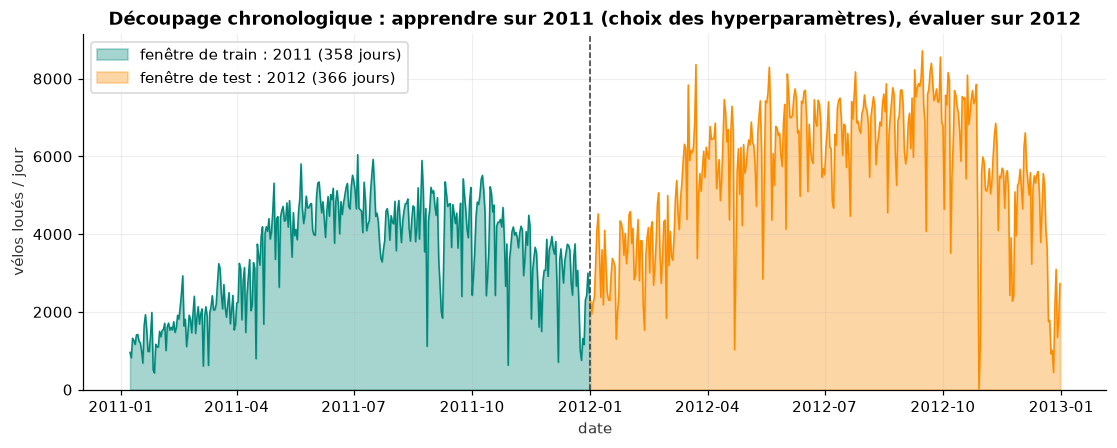

In [12]:
counts = y * TARGET_SCALE
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.fill_between(dates[is_train], 0, counts[is_train], color=PALETTE["teal"], alpha=0.35,
                label=f"fenêtre de train : 2011 ({is_train.sum()} jours)")
ax.fill_between(dates[~is_train], 0, counts[~is_train], color=PALETTE["orange"], alpha=0.35,
                label=f"fenêtre de test : 2012 ({(~is_train).sum()} jours)")
ax.plot(dates[is_train], counts[is_train], color=PALETTE["teal"], lw=1)
ax.plot(dates[~is_train], counts[~is_train], color=PALETTE["orange"], lw=1)
ax.axvline(pd.Timestamp("2012-01-01"), color="#333333", ls="--", lw=1)
ax.set_ylim(bottom=0)
ax.set(title="Découpage chronologique : apprendre sur 2011 (choix des hyperparamètres), évaluer sur 2012",
       xlabel="date", ylabel="vélos loués / jour")
ax.legend(loc="upper left")
plt.show()

**Lecture.** Le découpage suit la flèche du temps : rien de la fenêtre orange ne sert à choisir les hyperparamètres.
La fenêtre de test est **plus haute et plus variable** que celle de train. Un modèle qui se contenterait de reproduire le niveau de 2011
sous-estimerait 2012 en permanence : c'est pourquoi les modèles en ligne continuent de se mettre à jour pendant le test.

## 2.4 Modèle (i-a) — OGD sur la perte quadratique

On part de $\theta_1 = 0 \in \mathcal K$ avec un pas constant $\eta$, comme dans le théorème. La grille contient le pas théorique
$\eta^\star = D/(G\sqrt{T_{\text{train}}})$ et des pas plus grands. Le théorème raisonne dans le pire cas ; en pratique, un pas plus
grand suit souvent mieux une demande qui évolue.

In [13]:
def project_ball(theta, radius=B):
    """Projection euclidienne sur K = {θ : ||θ||₂ ≤ radius}."""
    norm = np.linalg.norm(theta)
    return theta if norm <= radius else theta * (radius / norm)


class OGD:
    """OGD projeté, perte quadratique ½(xᵀθ − y)², pas constant η."""

    def __init__(self, eta, d=X.shape[1], radius=B):
        self.eta, self.radius = eta, radius
        self.theta = np.zeros(d)

    def params(self):
        return self.theta

    def predict(self, x):
        return x @ self.theta

    def update(self, x, y):
        e = x @ self.theta - y                                                 # résidu e_t
        self.theta = project_ball(self.theta - self.eta * e * x, self.radius)  # θ ← Π_K(θ − η e_t x_t)


# Test de causalité de la boucle : changer y_t ne modifie pas la prédiction du jour t.
y_mod = y_test.copy()
y_mod[100] += 0.5
p_ref, _ = run_online(OGD(0.03), X_test, y_test)
p_mod, _ = run_online(OGD(0.03), X_test, y_mod)
assert np.allclose(p_ref[:101], p_mod[:101]) and not np.allclose(p_ref[101:], p_mod[101:])
print("Boucle causale : la prédiction du jour t n'utilise pas y_t.")

eta_star = D / (G_SQ * np.sqrt(len(y_train)))
OGD_GRID = sorted({round(eta_star, 4), 0.003, 0.01, 0.03, 0.1, 0.3})
best_eta, scores = select_on_train(OGD, OGD_GRID, squared_loss)
display(scores.rename("perte quadratique moyenne (train 2011)").to_frame().style.format("{:.5f}"))
print(f"η* théorique = {eta_star:.4f} ; η retenu sur le train = {best_eta}")

pred, params = train_then_test(OGD, best_eta)
results["OGD"] = {"pred": pred, "params": params, "hyper": f"η = {best_eta}"}
print("Coefficients en fin de test :", dict(zip(feature_names, params[-1].round(3))))

Boucle causale : la prédiction du jour t n'utilise pas y_t.


,perte quadratique moyenne (train 2011)
0.003000,0.01392
0.007100,0.00714
0.010000,0.00580
0.030000,0.00359
0.100000,0.00262
0.300000,0.00385


η* théorique = 0.0071 ; η retenu sur le train = 0.1
Coefficients en fin de test : {'intercept': np.float64(0.309), 'workingday': np.float64(0.072), 'holiday': np.float64(-0.038), 'temp': np.float64(0.194), 'windspeed': np.float64(-0.037), 'sin_annual': np.float64(0.108), 'cos_annual': np.float64(-0.182), 'weathersit_2': np.float64(-0.069), 'weathersit_3': np.float64(-0.255), 'weathersit_4': np.float64(0.0), 'y_lag1': np.float64(0.018), 'y_lag2': np.float64(-0.029), 'y_lag3': np.float64(-0.012), 'y_lag4': np.float64(0.007), 'y_lag5': np.float64(0.046), 'y_lag6': np.float64(0.082), 'y_lag7': np.float64(0.106)}


**Lecture.** Le pas théorique est petit : la garantie couvre le pire cas, et une suite favorable autorise un pas plus grand.
Les coefficients affichés portent désormais sur le calendrier, la température, le vent, les indicatrices météo et les retards de demande.
Leur importance doit être lue dans les résultats recalculés, et non supposée inchangée après l'ajout de variables.
Si un pas trop grand déstabilise l'algorithme, la projection sur $\mathcal K$ empêche les coefficients d'exploser :
c'est l'un des rôles pratiques du domaine compact.

## 2.5 Modèle (i-b) — OGD + Ridge

On applique OGD à $\widetilde\ell_t(\theta) = \tfrac12(\mathbf x_t^\top\theta - y_t)^2 + \tfrac\lambda2\|\theta\|_2^2$. La mise à jour **rétrécit** $\theta$ d'un facteur
$(1 - \eta_t\lambda)$, puis corrige dans la direction $\mathbf x_t$. L'horloge $t$ **n'est pas remise à zéro** au début du test.

**Le pas.** Le cours prend $\eta_t = 1/(\lambda t)$. Pour $\lambda$ petit, les premiers pas sont gigantesques ($\eta_1 = 1/\lambda$) : tant que
$\eta_t\|\mathbf x_t\|^2 > 2$, une correction dépasse sa cible et l'algorithme rebondit sur le bord de $\mathcal K$. Avec $\|\mathbf x_t\|^2 \le R^2$,
cela dure jusqu'à $t \approx R^2/(2\lambda)$ jours : plus de 2 100 jours avec $R^2=13$ et $\lambda = 0{,}003$, soit toute la série. On **plafonne** donc le pas :
$$
\eta_t = \min\Big\{\eta_{\max},\ \frac{1}{\lambda t}\Big\}, \qquad \eta_{\max} = \frac{1}{R^2},
$$
un plafond fixé **a priori** à partir de la borne $R$ de la Question 2.1. Dès que $t \ge R^2/\lambda$, on retrouve exactement le pas du cours ;
le plafond n'ajoute qu'un terme constant à la borne en $\log T$. Pour $\lambda$ petit, la phase plafonnée couvre toute la série :
OGD + Ridge se comporte alors comme OGD à pas $1/R^2$ avec un léger rétrécissement.

On choisit $\lambda$ sur le train avec l'erreur quadratique **non pénalisée**, car c'est la qualité de prévision qui nous intéresse.
Le regret de la partie 3 sera, lui, calculé sur la perte **pénalisée**, celle du théorème.

In [14]:
class OGDRidge(OGD):
    """OGD projeté sur la perte ridge ½(xᵀθ − y)² + λ/2 ||θ||², pas η_t = min(1/R², 1/(λ t))."""

    def __init__(self, lam, d=X.shape[1], radius=B, eta_max=1 / R**2):
        super().__init__(eta=None, d=d, radius=radius)
        self.lam, self.eta_max, self.t = lam, eta_max, 0

    def update(self, x, y):
        self.t += 1
        eta = min(self.eta_max, 1.0 / (self.lam * self.t))
        e = x @ self.theta - y
        self.theta = project_ball((1 - eta * self.lam) * self.theta - eta * e * x, self.radius)


RIDGE_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]
best_lam, scores = select_on_train(OGDRidge, RIDGE_GRID, squared_loss)
display(scores.rename("perte quadratique moyenne (train 2011)").to_frame().style.format("{:.5f}"))
print(f"η_max = 1/R² = {1 / R**2:.3f} ; λ retenu sur le train = {best_lam} "
      f"(pas du cours 1/(λt) atteint à partir de t = {R**2 / best_lam:.0f})")

pred, params = train_then_test(OGDRidge, best_lam)
results["OGD + Ridge"] = {"pred": pred, "params": params, "hyper": f"λ = {best_lam}", "lam": best_lam}
print("Coefficients en fin de test :", dict(zip(feature_names, params[-1].round(3))))
print(f"||θ|| en fin de test : Ridge = {np.linalg.norm(params[-1]):.3f}, "
      f"OGD = {np.linalg.norm(results['OGD']['params'][-1]):.3f}")

,perte quadratique moyenne (train 2011)
0.001000,0.00275
0.003000,0.00275
0.010000,0.00276
0.030000,0.00281
0.100000,0.00310
0.300000,0.00415


η_max = 1/R² = 0.077 ; λ retenu sur le train = 0.001 (pas du cours 1/(λt) atteint à partir de t = 13000)
Coefficients en fin de test : {'intercept': np.float64(0.279), 'workingday': np.float64(0.063), 'holiday': np.float64(-0.033), 'temp': np.float64(0.176), 'windspeed': np.float64(-0.022), 'sin_annual': np.float64(0.097), 'cos_annual': np.float64(-0.166), 'weathersit_2': np.float64(-0.068), 'weathersit_3': np.float64(-0.219), 'weathersit_4': np.float64(0.0), 'y_lag1': np.float64(0.066), 'y_lag2': np.float64(0.001), 'y_lag3': np.float64(0.002), 'y_lag4': np.float64(0.015), 'y_lag5': np.float64(0.045), 'y_lag6': np.float64(0.075), 'y_lag7': np.float64(0.089)}
||θ|| en fin de test : Ridge = 0.474, OGD = 0.526


**Lecture.** Deux effets s'opposent :

- **$\lambda$ petit :** peu de rétrécissement, et la phase plafonnée dure longtemps. On obtient presque OGD à pas $1/R^2$.
- **$\lambda$ grand :** on rejoint vite le pas $1/(\lambda t)$, qui décroît. Les coefficients sont fortement rétrécis vers 0, intercept compris,
  avec un biais vers des prédictions trop basses, et le pas devient vite trop petit pour suivre une demande qui croît.

Retirez le plafond (`eta_max=np.inf`) pour voir le comportement du pas brut $1/(\lambda t)$ sur le train.
Ridge gagne une garantie en $\log T$, mais sur un **autre objectif** : ce n'est pas automatiquement une meilleure prévision quadratique.

## 2.6 Modèle (ii) — Perte newsvendor

### Vérification empirique : l'optimum est le quantile $\tau = c_b/(c_b + c_h)$

Sur la fenêtre de train, on calcule le coût moyen $\frac1n\sum_t \ell_t(q)$ d'une commande **constante** $q$ sur une grille fine,
et on compare son minimiseur au $\tau$-quantile empirique de $(y_t)$. On répète l'expérience pour plusieurs couples $(c_b, c_h)$.

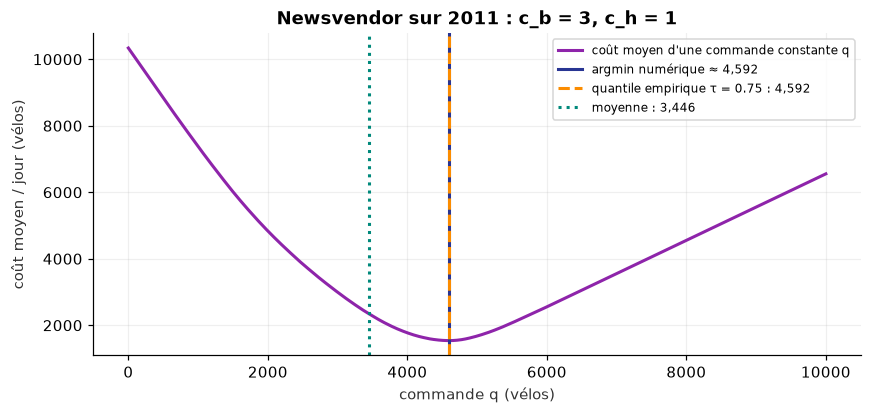

,c_b,c_h,τ,argmin numérique,quantile empirique
0,1,1,0.50,3750.0,3750.0
1,1,3,0.25,2210.0,2209.0
2,3,1,0.75,4592.0,4592.0
3,9,1,0.90,4990.0,4991.0


In [15]:
q_grid = np.linspace(0.0, Q_MAX, 4001)
cost = np.array([newsvendor_loss(q, y_train).mean() for q in q_grid])
q_argmin = q_grid[cost.argmin()]
q_quantile = np.quantile(y_train, TAU, method="inverted_cdf")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(q_grid * TARGET_SCALE, cost * TARGET_SCALE, color=PALETTE["purple"], label="coût moyen d'une commande constante q")
ax.axvline(q_argmin * TARGET_SCALE, color=PALETTE["darkblue"], lw=2, label=f"argmin numérique ≈ {q_argmin * TARGET_SCALE:,.0f}")
ax.axvline(q_quantile * TARGET_SCALE, color=PALETTE["orange"], ls="--", lw=2,
           label=f"quantile empirique τ = {TAU} : {q_quantile * TARGET_SCALE:,.0f}")
ax.axvline(y_train.mean() * TARGET_SCALE, color=PALETTE["teal"], ls=":", lw=2,
           label=f"moyenne : {y_train.mean() * TARGET_SCALE:,.0f}")
ax.set(title="Newsvendor sur 2011 : c_b = 3, c_h = 1", xlabel="commande q (vélos)", ylabel="coût moyen / jour (vélos)")
ax.legend(fontsize=8)
plt.show()

rows = []
for c_b, c_h in [(1, 1), (1, 3), (3, 1), (9, 1)]:
    tau = c_b / (c_b + c_h)
    c = np.array([newsvendor_loss(q, y_train, c_b, c_h).mean() for q in q_grid])
    rows.append({"c_b": c_b, "c_h": c_h, "τ": tau,
                 "argmin numérique": q_grid[c.argmin()] * TARGET_SCALE,
                 "quantile empirique": np.quantile(y_train, tau, method="inverted_cdf") * TARGET_SCALE})
display(pd.DataFrame(rows).round({"τ": 3, "argmin numérique": 0, "quantile empirique": 0}))

**Lecture.** L'argmin numérique coïncide avec le $\tau$-quantile empirique, à la résolution de la grille près. Le coût est linéaire par morceaux,
avec des cassures aux valeurs observées. Quand $n\tau$ est entier, l'argmin est tout un **intervalle** entre deux observations : c'est la condition
$F(q^{\star-}) \le \tau \le F(q^\star)$ du cours. Avec $c_b = c_h$, on retrouve la **médiane**. Plus la rupture est chère, plus on commande haut,
et commander la **moyenne** coûte plus cher.

### OGD newsvendor sans covariable

C'est l'algorithme des slides 63–64 : $q_{t+1} = \Pi_{[0, Q_{\max}]}(q_t - \eta\, g_t)$. Aucune covariable n'est utilisée, mais la commande
$q_t$ **bouge chaque jour** : rupture, on monte de $\eta c_b$ ; excédent, on baisse de $\eta c_h$. Le **comparateur**, lui, est une seule commande
constante choisie a posteriori : le quantile empirique écrêté.

In [16]:
class NewsvendorOGD:
    """Commande q_t ∈ [0, Q_max] sans covariable, apprise par sous-gradient projeté."""

    def __init__(self, eta, q0=0.0, q_max=Q_MAX):
        self.eta, self.q, self.q_max = eta, q0, q_max

    def params(self):
        return np.array([self.q])

    def predict(self, x):
        return self.q  # ignore les covariables

    def update(self, x, y):
        g = C_H if self.q > y else (-C_B if self.q < y else 0.0)  # excédent : +c_h ; rupture : −c_b
        self.q = float(np.clip(self.q - self.eta * g, 0.0, self.q_max))


eta_nv_star = Q_MAX / (G_NV * np.sqrt(len(y_train)))
NV_GRID = sorted({round(eta_nv_star, 4), 0.001, 0.003, 0.01, 0.03})
best_eta_nv, scores = select_on_train(NewsvendorOGD, NV_GRID, newsvendor_loss)
display(scores.rename("coût newsvendor moyen (train 2011)").to_frame().style.format("{:.5f}"))
print(f"η* théorique = {eta_nv_star:.4f} ; η retenu = {best_eta_nv}")

pred, params = train_then_test(NewsvendorOGD, best_eta_nv)
results["Newsvendor (sans covariable)"] = {"pred": pred, "params": params, "hyper": f"η = {best_eta_nv}"}
print(f"Fréquence des jours sans rupture sur 2012, P(y_t ≤ q_t) = {np.mean(y_test <= pred):.3f} (cible τ = {TAU})")

,coût newsvendor moyen (train 2011)
0.001000,0.17730
0.003000,0.09053
0.010000,0.08073
0.017600,0.08117
0.030000,0.09265


η* théorique = 0.0176 ; η retenu = 0.01
Fréquence des jours sans rupture sur 2012, P(y_t ≤ q_t) = 0.740 (cible τ = 0.75)


### OGD newsvendor contextuel : un quantile conditionnel

On remplace la commande sans covariable par $q_t = \mathbf x_t^\top\theta_t$, avec $\theta_t \in \mathcal K$. Le sous-gradient devient
$g_t = \big(c_h\,\mathbf 1\{q_t > y_t\} - c_b\,\mathbf 1\{q_t < y_t\}\big)\,\mathbf x_t$. On apprend ainsi un **quantile conditionnel**
de niveau $\tau$ qui exploite le calendrier, la météo du jour supposée connue et la demande récente.

*Remarque.* Rien n'impose $q_t \in [0, Q_{\max}]$ pour un modèle linéaire. On le vérifie a posteriori ; en déploiement, on écrêterait la commande.

In [17]:
class ContextualNewsvendorOGD(OGD):
    """q_t = x_tᵀθ_t, sous-gradient de la perte newsvendor, projection sur K."""

    def update(self, x, y):
        q = x @ self.theta
        g = C_H if q > y else (-C_B if q < y else 0.0)
        self.theta = project_ball(self.theta - self.eta * g * x, self.radius)


CTX_GRID = sorted({round(D / (G_CTX * np.sqrt(len(y_train))), 4), 0.0003, 0.001, 0.003, 0.01})
best_eta_ctx, scores = select_on_train(ContextualNewsvendorOGD, CTX_GRID, newsvendor_loss)
display(scores.rename("coût newsvendor moyen (train 2011)").to_frame().style.format("{:.5f}"))
print(f"η retenu = {best_eta_ctx}")

pred, params = train_then_test(ContextualNewsvendorOGD, best_eta_ctx)
results["Newsvendor (contextuel)"] = {"pred": pred, "params": params, "hyper": f"η = {best_eta_ctx}"}
print(f"P(y_t ≤ q_t) sur 2012 = {np.mean(y_test <= pred):.3f} (cible τ = {TAU})")
print(f"Commandes hors de [0, Q_max] : {np.mean((pred < 0) | (pred > Q_MAX)):.1%} des jours")

,coût newsvendor moyen (train 2011)
0.000300,0.23907
0.001000,0.11457
0.003000,0.08855
0.010000,0.10310
0.019500,0.15477


η retenu = 0.003
P(y_t ≤ q_t) sur 2012 = 0.738 (cible τ = 0.75)
Commandes hors de [0, Q_max] : 0.0% des jours


## 2.7 Références naïves

Un algorithme n'a de valeur que comparé à une référence simple. On ajoute deux prédicteurs qui n'apprennent rien :
la **veille** ($\widehat y_t = y_{t-1}$) et la **semaine précédente** ($\widehat y_t = y_{t-7}$). La veille correspond au paramètre fixe
$\theta = e_{\texttt{y\_lag1}}$, de norme $1 \le B$ : c'est un point de $\mathcal K$, donc un concurrent légitime du comparateur.

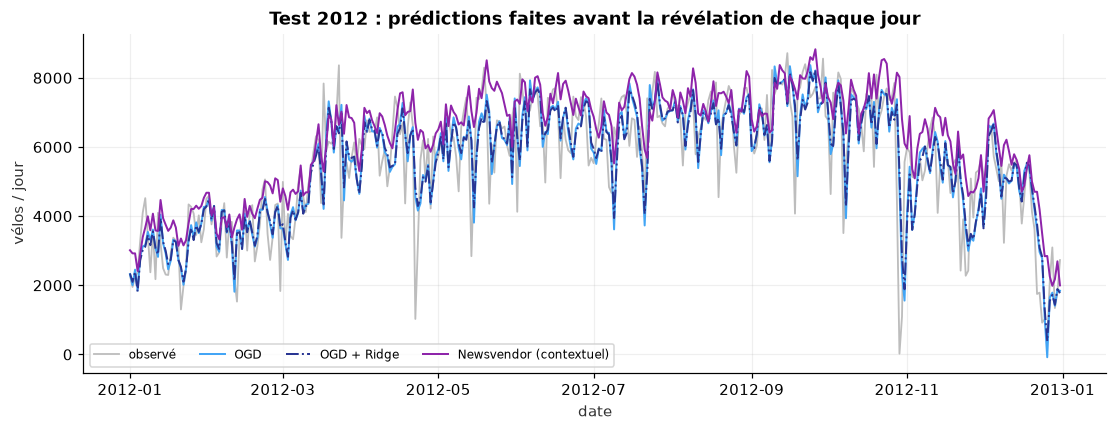

In [18]:
class LagBaseline:
    """Prédit la valeur observée k jours plus tôt (aucun apprentissage)."""

    def __init__(self, k):
        self.j = feature_names.index(f"y_lag{k}")

    def params(self):
        return np.zeros(0)

    def predict(self, x):
        return x[self.j]

    def update(self, x, y):
        pass


for name, k in [("Naïf (veille)", 1), ("Naïf (J-7)", 7)]:
    pred, params = run_online(LagBaseline(k), X_test, y_test)
    results[name] = {"pred": pred, "params": params, "hyper": "—"}

ORDER = ["Naïf (veille)", "Naïf (J-7)", "OGD", "OGD + Ridge", "Newsvendor (sans covariable)", "Newsvendor (contextuel)"]
results = {name: results[name] for name in ORDER}

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates_test, y_test * TARGET_SCALE, color="#BDBDBD", lw=1.2, label="observé")
for name in ["OGD", "OGD + Ridge", "Newsvendor (contextuel)"]:
    ax.plot(dates_test, results[name]["pred"] * TARGET_SCALE, color=COLORS[name], ls=STYLES[name], lw=1.3, label=name)
ax.set(title="Test 2012 : prédictions faites avant la révélation de chaque jour", xlabel="date", ylabel="vélos / jour")
ax.legend(fontsize=8, ncol=4)
plt.show()

# Partie 3 — Métriques finales

Toutes les métriques portent sur les **366 jours de 2012**, avec les prédictions faites avant chaque révélation de la demande.
Les modèles contextuels (OGD, Ridge et newsvendor contextuel) utilisent désormais la météo du jour supposée connue ;
les deux références naïves et le newsvendor sans covariable n'utilisent pas cette information.
Les erreurs sont reconverties en **vélos par jour**. Le biais est noté *prédit − observé* : positif, on surestime.
On ajoute le coût newsvendor et la couverture $\mathbb P(y_t \le \widehat y_t)$, qui doit valoir environ $\tau = 0{,}75$ pour un bon quantile.

In [19]:
def final_metrics(pred, y):
    err = (pred - y) * TARGET_SCALE
    return {
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "MAE": np.mean(np.abs(err)),
        "Biais (prédit − observé)": np.mean(err),
        "Coût newsvendor / jour": newsvendor_loss(pred, y).mean() * TARGET_SCALE,
        "Couverture P(y ≤ ŷ)": np.mean(y <= pred),
    }


scorecard = pd.DataFrame({name: final_metrics(r["pred"], y_test) for name, r in results.items()}).T
scorecard.insert(0, "hyperparamètre", [r["hyper"] for r in results.values()])
display(scorecard.style.format({"RMSE": "{:,.0f}", "MAE": "{:,.0f}", "Biais (prédit − observé)": "{:+,.0f}",
                                "Coût newsvendor / jour": "{:,.0f}", "Couverture P(y ≤ ŷ)": "{:.2f}"}))

,hyperparamètre,RMSE,MAE,Biais (prédit − observé),Coût newsvendor / jour,Couverture P(y ≤ ŷ)
Naïf (veille),—,"1,246",870,-1,"1,741",0.46
Naïf (J-7),—,"1,562","1,110",+2,"2,218",0.48
OGD,η = 0.1,"1,041",747,-27,"1,520",0.47
OGD + Ridge,λ = 0.001,"1,031",737,-30,"1,503",0.47
Newsvendor (sans covariable),η = 0.01,"1,461","1,014",+795,"1,232",0.74
Newsvendor (contextuel),η = 0.003,"1,295",909,+669,"1,149",0.74


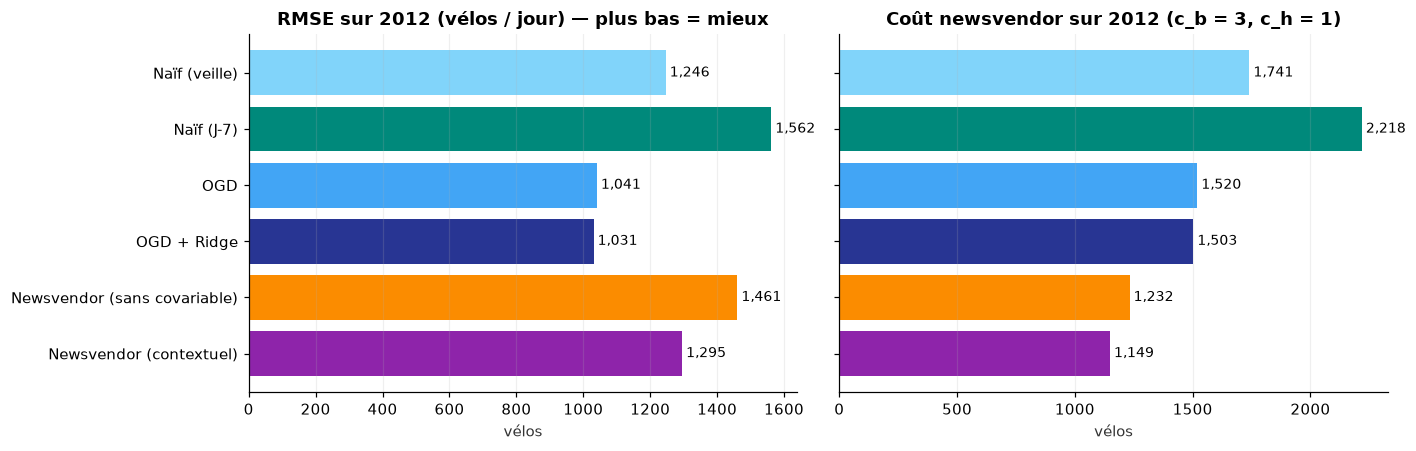

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
panels = [("RMSE", "RMSE sur 2012 (vélos / jour) — plus bas = mieux"),
          ("Coût newsvendor / jour", f"Coût newsvendor sur 2012 (c_b = {C_B:g}, c_h = {C_H:g})")]
for ax, (col, title) in zip(axes, panels):
    values = scorecard[col].astype(float)
    ax.barh(values.index, values.values, color=[COLORS[n] for n in values.index])
    for i, v in enumerate(values.values):
        ax.text(v, i, f" {v:,.0f}", va="center", fontsize=9)
    ax.invert_yaxis()
    ax.set(title=title, xlabel="vélos")
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

<div style="border-left:4px solid #8E24AA;padding:8px 14px;background:#F3E5F5;color:black">
<b>RMSE et coût newsvendor répondent à deux besoins différents.</b><br>
Les deux familles ne répondent pas au même besoin.

- Les modèles quadratiques (OGD, OGD + Ridge) répondent à <b>« combien de vélos seront loués ? »</b>. Ils visent la <b>moyenne</b>
  conditionnelle, et le RMSE est le score naturel de cette question.
- Les modèles newsvendor répondent à <b>« combien de vélos dois-je mettre à disposition ? »</b>, sachant qu'une rupture coûte trois fois
  plus cher qu'un vélo immobilisé. Ils visent le <b>quantile 0,75</b> et commandent donc volontairement au-dessus de la demande attendue :
  biais positif, environ 75 % de jours sans rupture, un RMSE plus élevé et un coût newsvendor plus faible.

Chaque modèle se juge avec la perte de la décision qu'il éclaire. Classer les modèles newsvendor au RMSE, ou les modèles quadratiques
au coût newsvendor, reviendrait à comparer les réponses à deux questions différentes.
</div>

**Lecture.**

- **Chaque modèle est bon pour la perte qu'il optimise.** Le panneau de gauche récompense la prévision de la moyenne, celui de droite la décision de stock.
- **Le newsvendor sans covariable** suit le niveau de la demande avec retard, puisque $q_t$ est corrigé chaque jour. Il ne voit ni le jour
  de la semaine, ni les fériés, ni la météo : le modèle contextuel peut exploiter ces informations pour adapter ses commandes.
- **OGD contre les références naïves :** battre la veille n'est pas garanti. La veille est déjà un très bon prédicteur d'une série
  aussi persistante, et c'est elle qui juge l'intérêt réel d'un algorithme.
- **Ridge contre OGD :** le rétrécissement et le pas décroissant peuvent coûter en précision, même si la garantie théorique est meilleure.

## Regret moyen au cours du temps

Pour chaque préfixe de $n$ jours de test, on calcule
$$
\frac{R_n}{n} = \frac1n\Big(\sum_{j=1}^n \ell_j(\theta_j) - \min_{u \in \mathcal K}\sum_{j=1}^n \ell_j(u)\Big),
$$
**chaque modèle avec sa propre perte**, c'est-à-dire celle de son théorème. Le comparateur est **un seul** paramètre fixe par préfixe, recalculé à chaque $n$.

- **Quadratique (et ridge) :** $\min_{\|u\|\le B} \tfrac12 u^\top A u - b^\top u$ avec $A = \sum \mathbf x_j\mathbf x_j^\top$ (plus $n\lambda I$ pour le ridge)
  et $b = \sum y_j \mathbf x_j$. Si la solution des moindres carrés est dans la boule, c'est elle. Sinon, conditions KKT :
  $(A + \mu I)u = b$ avec $\|u\| = B$ et $\mu > 0$, où l'on cherche $\mu$ par recherche de racine.
- **Newsvendor sans covariable :** le comparateur est une commande constante ; le coût est linéaire par morceaux, donc l'optimum est atteint en $0$, en $Q_{\max}$ ou en une valeur observée.
- **Newsvendor contextuel :** régression quantile, résolue par un programme linéaire. On vérifie que la solution est dans la boule.
  Si elle n'y est pas, le comparateur calculé est trop bon et la courbe surestime le regret : c'est une borne supérieure prudente.

In [21]:
def constrained_quadratic_min(A, b, radius=B):
    """argmin_{||u||₂ ≤ radius} ½ uᵀAu − bᵀu, pour A symétrique semi-définie positive."""
    w, V = np.linalg.eigh(A)
    w = np.clip(w, 0.0, None)
    c = V.T @ b
    in_range = w > 1e-12 * max(w.max(), 1.0)
    # 1) contrainte inactive : solution de norme minimale de Au = b, si elle existe et est admissible
    if np.allclose(c[~in_range], 0.0, atol=1e-12):
        u = V[:, in_range] @ (c[in_range] / w[in_range])
        if np.linalg.norm(u) <= radius:
            return u
    # 2) contrainte active : (A + μI)u = b et ||u|| = radius, avec μ > 0 trouvé par recherche de racine
    norm_u = lambda mu: np.linalg.norm(c / (w + mu))
    mu = brentq(lambda m: norm_u(m) - radius, 1e-15, np.linalg.norm(c) / radius) if norm_u(1e-15) > radius else 1e-15
    return V @ (c / (w + mu))


def avg_regret_quadratic(X, y, pred, params=None, lam=0.0):
    """R_n / n pour la perte quadratique (lam = 0) ou ridge (lam > 0), à chaque préfixe n."""
    d = X.shape[1]
    A, b, yy, loss_alg = np.zeros((d, d)), np.zeros(d), 0.0, 0.0
    out = np.empty(len(y))
    for n in range(len(y)):
        x = X[n]
        A += np.outer(x, x); b += y[n] * x; yy += y[n] ** 2
        loss_alg += squared_loss(pred[n], y[n]) + (0.5 * lam * params[n] @ params[n] if lam > 0 else 0.0)
        A_n = A + (n + 1) * lam * np.eye(d)
        u = constrained_quadratic_min(A_n, b)
        loss_star = 0.5 * u @ A_n @ u - b @ u + 0.5 * yy
        out[n] = (loss_alg - loss_star) / (n + 1)
    return out


def avg_regret_newsvendor_constant(y, q):
    """R_n / n contre la meilleure commande constante dans [0, Q_max]."""
    loss_alg = np.cumsum(newsvendor_loss(q, y))
    out = np.empty(len(y))
    for n in range(1, len(y) + 1):
        candidates = np.clip(np.concatenate([[0.0, Q_MAX], y[:n]]), 0.0, Q_MAX)
        loss_star = newsvendor_loss(candidates[:, None], y[None, :n]).sum(axis=1).min()
        out[n - 1] = (loss_alg[n - 1] - loss_star) / n
    return out


def avg_regret_newsvendor_contextual(X, y, q):
    """R_n / n contre la meilleure régression quantile linéaire fixe (programme linéaire)."""
    loss_alg = np.cumsum(newsvendor_loss(q, y))
    out, inside = np.empty(len(y)), np.empty(len(y), dtype=bool)
    d = X.shape[1]
    for n in range(1, len(y) + 1):
        cost = np.concatenate([np.zeros(d), C_B * np.ones(n), C_H * np.ones(n)])  # θ, (y−q)+, (q−y)+
        A_eq = np.hstack([X[:n], np.eye(n), -np.eye(n)])                          # xᵀθ + u⁺ − u⁻ = y
        res = linprog(cost, A_eq=A_eq, b_eq=y[:n], bounds=[(None, None)] * d + [(0, None)] * (2 * n), method="highs")
        out[n - 1] = (loss_alg[n - 1] - res.fun) / n
        inside[n - 1] = np.linalg.norm(res.x[:d]) <= B
    return out, inside


avg_regret = {
    "Naïf (veille)": avg_regret_quadratic(X_test, y_test, results["Naïf (veille)"]["pred"]),
    "OGD": avg_regret_quadratic(X_test, y_test, results["OGD"]["pred"]),
    "OGD + Ridge": avg_regret_quadratic(X_test, y_test, results["OGD + Ridge"]["pred"],
                                        results["OGD + Ridge"]["params"], lam=results["OGD + Ridge"]["lam"]),
    "Newsvendor (sans covariable)": avg_regret_newsvendor_constant(y_test, results["Newsvendor (sans covariable)"]["pred"]),
}
avg_regret["Newsvendor (contextuel)"], inside = avg_regret_newsvendor_contextual(
    X_test, y_test, results["Newsvendor (contextuel)"]["pred"])
print(f"Comparateur contextuel dans K pour {inside.mean():.0%} des préfixes "
      f"({inside[30:].mean():.0%} après 30 jours).")

Comparateur contextuel dans K pour 95% des préfixes (100% après 30 jours).


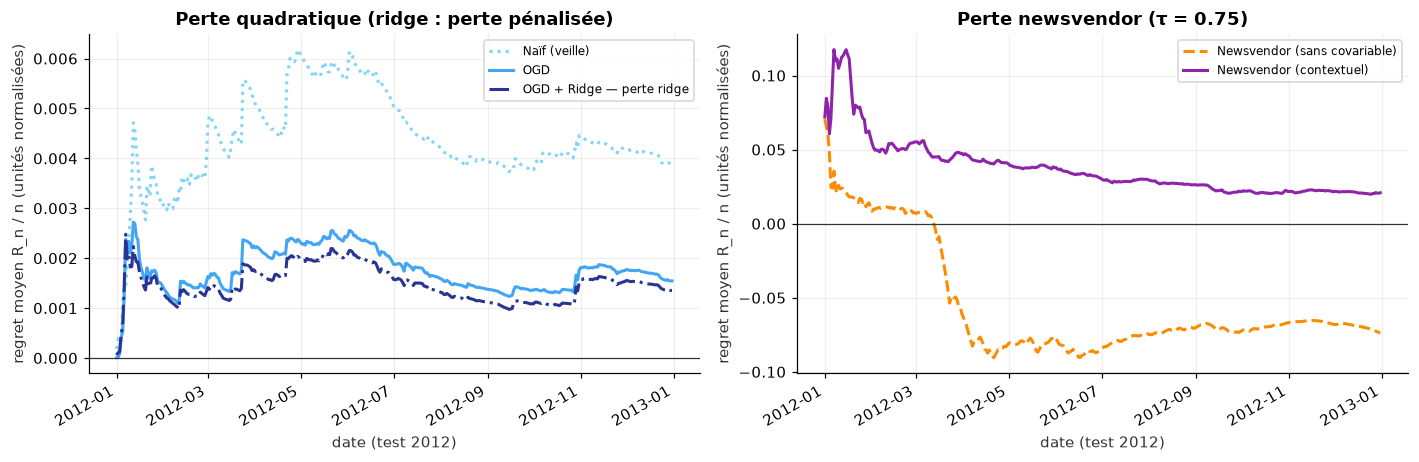

,R_n / n en fin de test
Naïf (veille),+0.00390
OGD,+0.00154
OGD + Ridge,+0.00135
Newsvendor (sans covariable),-0.07385
Newsvendor (contextuel),+0.02085


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharex=True)
panels = [
    (axes[0], ["Naïf (veille)", "OGD", "OGD + Ridge"], "Perte quadratique (ridge : perte pénalisée)"),
    (axes[1], ["Newsvendor (sans covariable)", "Newsvendor (contextuel)"], f"Perte newsvendor (τ = {TAU})"),
]
for ax, names, title in panels:
    for name in names:
        label = name + (" — perte ridge" if name == "OGD + Ridge" else "")
        ax.plot(dates_test, avg_regret[name], color=COLORS[name], ls=STYLES[name], label=label)
    ax.axhline(0, color="#333333", lw=0.8)
    ax.set(title=title, xlabel="date (test 2012)", ylabel="regret moyen R_n / n (unités normalisées)")
    ax.legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

display(pd.Series({name: r[-1] for name, r in avg_regret.items()},
                  name="R_n / n en fin de test").to_frame().style.format("{:+.5f}"))

**Lecture.**

- **Le regret peut être négatif, et fortement.** Le newsvendor sans covariable en est l'exemple type : sa commande suit la croissance
  de 2012, alors que le comparateur est **une seule** commande pour toute l'année, trop haute en hiver et trop basse en été.
  Battre ce comparateur ne dit donc pas grand-chose. La garantie ne contrôle que $\max(R_n, 0)/n$.
- **Le comparateur dépend de la classe de modèles.** Le newsvendor contextuel affronte une régression quantile linéaire fixe, bien plus forte
  qu'une constante : son regret est positif alors que son coût est du même ordre.
- **Les premiers jours sont bruités :** pour $n$ petit, le comparateur s'ajuste presque parfaitement aux quelques points vus, d'où un regret moyen élevé.
  La courbe se stabilise ensuite.
- **La veille** a un regret moyen qui ne tend pas vers 0 : c'est un paramètre fixe de $\mathcal K$ qui n'est pas le meilleur. Un regret moyen faible
  ne signifie pas pour autant une erreur faible : il mesure l'écart à **un** comparateur, pas la qualité absolue.
- **Ridge :** son regret est mesuré sur la perte pénalisée ; il n'est pas directement comparable aux deux autres courbes du panneau.
- **Une courbe finie ne prouve rien d'asymptotique.** Elle illustre la garantie sans la démontrer, et les bornes théoriques calculées en Question 2.1 sont bien au-dessus.

## Conclusion

La cellule ci-dessous résume **vos** résultats chiffrés. Les messages qui suivent ne dépendent pas des chiffres exacts.

In [23]:
print("Scénario : temp, weathersit et windspeed du jour t connues avant la décision.")
best_rmse = scorecard["RMSE"].astype(float).idxmin()
best_cost = scorecard["Coût newsvendor / jour"].astype(float).idxmin()
ogd_vs_naive = scorecard.loc["OGD", "RMSE"] / scorecard.loc["Naïf (veille)", "RMSE"] - 1
print(f"• Meilleur RMSE sur 2012 : {best_rmse} ({scorecard.loc[best_rmse, 'RMSE']:,.0f} vélos / jour).")
print(f"• OGD contre la veille : RMSE {ogd_vs_naive:+.1%}.")
print(f"• Meilleur coût newsvendor : {best_cost} ({scorecard.loc[best_cost, 'Coût newsvendor / jour']:,.0f} / jour).")
print(f"• Couverture P(y ≤ q) : sans covariable = {scorecard.loc['Newsvendor (sans covariable)', 'Couverture P(y ≤ ŷ)']:.2f}, "
      f"contextuel = {scorecard.loc['Newsvendor (contextuel)', 'Couverture P(y ≤ ŷ)']:.2f} (cible {TAU}).")
print("• Regret moyen final : " + ", ".join(f"{k} {v[-1]:+.4f}" for k, v in avg_regret.items()) + ".")

Scénario : temp, weathersit et windspeed du jour t connues avant la décision.
• Meilleur RMSE sur 2012 : OGD + Ridge (1,031 vélos / jour).
• OGD contre la veille : RMSE -16.5%.
• Meilleur coût newsvendor : Newsvendor (contextuel) (1,149 / jour).
• Couverture P(y ≤ q) : sans covariable = 0.74, contextuel = 0.74 (cible 0.75).
• Regret moyen final : Naïf (veille) +0.0039, OGD +0.0015, OGD + Ridge +0.0014, Newsvendor (sans covariable) -0.0739, Newsvendor (contextuel) +0.0209.


**Messages à retenir.**

1. **La perte définit la décision.** La perte quadratique vise la moyenne conditionnelle, la perte newsvendor le quantile $\tau = c_b/(c_b+c_h)$.
   Nous l'avons vérifié : la meilleure commande constante est le quantile empirique, et une politique newsvendor en ligne couvre environ $\tau$ des jours.
   Un modèle newsvendor au RMSE plus élevé n'est pas un moins bon modèle : il répond à une autre question.
2. **Un seul algorithme pour tout faire :** un (sous-)gradient, puis une projection. Seuls la perte et le pas changent.
3. **Les hypothèses se construisent.** Compacité de $\mathcal K$, covariables et cible bornées : on les obtient par des choix de modélisation
   déclarés **a priori** (échelle, covariables bornées, rayon $B$), jamais estimés sur le test.
4. **Le protocole compte autant que l'algorithme :** prédire avant d'apprendre, couper par les dates, choisir les hyperparamètres sur le train
   et comparer à des références naïves. La météo du jour n'est admissible ici que parce qu'on la suppose connue avant la décision ;
   les résultats sont conditionnels à cette hypothèse, et ne mesurent pas la qualité de véritables prévisions météo.
5. **Le regret a ses limites.** Il compare à un paramètre **fixe** : sur une demande qui croît, être sans regret ne garantit ni une petite erreur
   ni un bon suivi. Pour cela, il faudrait un regret **dynamique**, contre une suite de comparateurs qui varie lentement.

**Pour aller plus loin.** Comparer la météo observée supposée connue, une vraie prévision météo et une variante sans météo ; remplacer le pas constant par $\eta_t = \eta_0/\sqrt t$ ; mesurer le regret contre
un comparateur par trimestre ; se demander ce que mesure vraiment `cnt` comme « demande », puisque les jours de rupture de stations, la demande non servie n'est pas observée.